You are provided with the Geron’s notebook from chapter 18 of his PyTorch book, 
18_autoencoders_gans_and_diffusion_models.ipynb.Please create your own 
notebook only with your solutions to the following problems. Please do not submit 
modified version of Geron’s notebook. 

## Problem 1.  
Plots of training data on slides 24 and 28 are actually from another example and not from the above notebook. Use the following code to generate a new set of 3D data X_train : 

```
import numpy as np 
np.random.seed(4) 
def generate_3d_data(m, w1=0.1, w2=0.3, noise=0.1): 
    angles = np.random.rand(m) * 3 * np.pi / 2 - 0.5 
    data = np.empty((m, 3)) 
    data[:, 0] = np.cos(angles) + np.sin(angles)/2 + noise * np.random.randn(m) / 2 
    data[:, 1] = np.sin(angles) * 0.7 + noise * np.random.randn(m) / 2 
    data[:, 2] = data[:, 0] * w1 + data[:, 1] * w2 + noise * np.random.randn(m) 
    return data 
 
X_train = generate_3d_data(60) 
X_train = X_train - X_train.mean(axis=0, keepdims=0) 
```
 
Create validation data, train the autoencoder with code given on slide 25 and plot resulting 2D codings

In [1]:
# setup
import numpy as np 
import matplotlib as mpl
import matplotlib.pyplot as plt
import plotly.express as px
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import torchmetrics
from mpl_toolkits.mplot3d import Axes3D
np.random.seed(4) 
torch.manual_seed(42)

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

device

'cuda'

In [ ]:
# train() and evaluate_tm() are reused (unchanged) from Geron's notebook
def evaluate_tm(model, data_loader, metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            if isinstance(y_pred, tuple):
                y_pred = y_pred.output
            metric.update(y_pred, y_batch)
    return metric.compute()

def train(model, optimizer, loss_fn, metric, train_loader, valid_loader,
          n_epochs, patience=2, factor=0.5, epoch_callback=None):
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", patience=patience, factor=factor)
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    for epoch in range(n_epochs):
        total_loss = 0.0
        metric.reset()
        model.train()
        if epoch_callback is not None:
            epoch_callback(model, epoch)
        for index, (X_batch, y_batch) in enumerate(train_loader):
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            optimizer.zero_grad()
            if isinstance(y_pred, tuple):
                y_pred = y_pred.output
            metric.update(y_pred, y_batch)
            train_metric = metric.compute().item()
            print(f"\rBatch {index + 1}/{len(train_loader)}", end="")
            print(f", loss={total_loss/(index+1):.4f}", end="")
            print(f", {train_metric=:.3f}", end="")
        history["train_losses"].append(total_loss / len(train_loader))
        history["train_metrics"].append(train_metric)
        val_metric = evaluate_tm(model, valid_loader, metric).item()
        history["valid_metrics"].append(val_metric)
        scheduler.step(val_metric)
        print(f"\rEpoch {epoch + 1}/{n_epochs},                      "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.3}, "
              f"valid metric: {history['valid_metrics'][-1]:.3}")
    return history

x_train: (60, 3)


x_valid: (500, 3)
ok
Epoch 1/20,                      train loss: 0.2730, train metric: 0.524, valid metric: 0.337
Epoch 2/20,                      train loss: 0.0853, train metric: 0.293, valid metric: 0.238
Epoch 3/20,                      train loss: 0.0537, train metric: 0.233, valid metric: 0.221
Epoch 4/20,                      train loss: 0.0478, train metric: 0.219, valid metric: 0.211
Epoch 5/20,                      train loss: 0.0439, train metric: 0.21, valid metric: 0.198
Epoch 6/20,                      train loss: 0.0376, train metric: 0.194, valid metric: 0.18
Epoch 7/20,                      train loss: 0.0301, train metric: 0.173, valid metric: 0.152
Epoch 8/20,                      train loss: 0.0215, train metric: 0.147, valid metric: 0.131
Epoch 9/20,                      train loss: 0.0156, train metric: 0.125, valid metric: 0.112
Epoch 10/20,                      train loss: 0.0118, train metric: 0.109, valid metric: 0.0967
Epoch 11/20,                      train

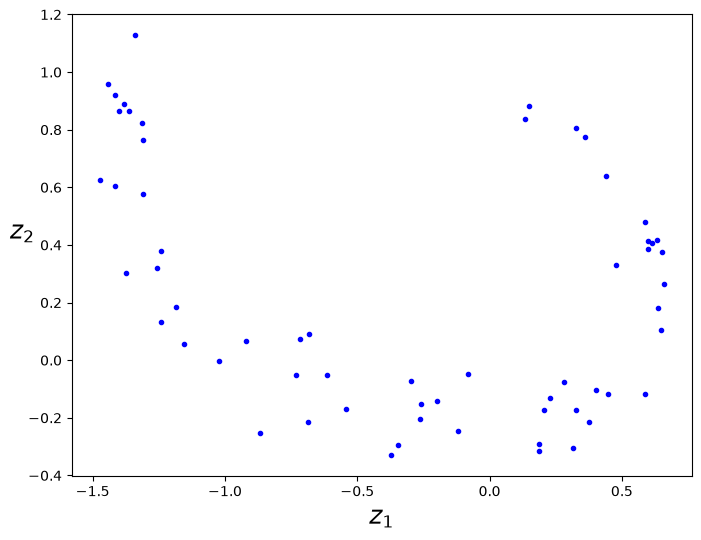

In [ ]:


def generate_3d_data(m, w1=0.1, w2=0.3, noise=0.1): 
    angles = np.random.rand(m) * 3 * np.pi / 2 - 0.5  #uneven distribution
    data = np.empty((m, 3))  #initialize 3d dataset
    data[:, 0] = np.cos(angles) + np.sin(angles)/2 + noise *  np.random.randn(m) / 2 #oval with noise
    data[:, 1] = np.sin(angles) * 0.7 + noise *  np.random.randn(m) / 2 
    data[:, 2] = data[:, 0] * w1 + data[:, 1] * w2 + noise *  np.random.randn(m) 
    return data 

# Generate new sets of 3D data
X_train = generate_3d_data(60)
X_valid = generate_3d_data(500)

#center both datasets using the training mean
train_mean = X_train.mean(axis=0, keepdims=True)

X_train = X_train - train_mean
X_valid = X_valid - train_mean

# checking out how it looks
print(f"x_train: {X_train.shape}")
fig = px.scatter_3d(X_train, x=0, y=1, z=2, labels={"0": "x1", "1": "x2", "2": "x3"})
fig.show()

print(f"x_valid: {X_valid.shape}")

# convert NumPy arrays to PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
X_valid = torch.tensor(X_valid, dtype=torch.float32)

# Create datasets
train_set = TensorDataset(X_train, X_train)
valid_set = TensorDataset(X_valid, X_valid)

# Create data loaders
train_loader = DataLoader(
    train_set,
    batch_size=32,
    shuffle=True
)

valid_loader = DataLoader(
    valid_set,
    batch_size=32
)
print("ok")

#autoencoder
encoder = nn.Linear(3, 2)
decoder = nn.Linear(2, 3)
autoencoder = nn.Sequential(encoder, decoder).to(device)

optimizer = torch.optim.NAdam(autoencoder.parameters(), lr=0.2)
mse = nn.MSELoss()
rmse = torchmetrics.MeanSquaredError(squared=False).to(device)
history = train(autoencoder, optimizer, mse, rmse, train_loader, valid_loader, n_epochs=20)

codings = encoder(X_train.to(device)).detach().cpu().numpy()

# another visual
%matplotlib inline
fig = plt.figure(figsize=(8, 6))
plt.plot(codings[:, 0], codings[:, 1], "b.")
plt.xlabel("$z_1$", fontsize=18)
plt.ylabel("$z_2$", fontsize=18, rotation=0)
plt.show()

## Problem 2
Train a deep autoencoder with the architecture presented on slide 33 and 
train it on MNIST data (images of handwritten digits). Present the original images of the first 5 elements of that data set and their reconstructed images.  

Load MNIST and split it the same way Géron splits Fashion MNIST (55,000 training / 5,000 validation). Each sample is wrapped so that the target equals the input.

In [4]:
import torchvision
import torchvision.transforms.v2 as T
import torch.nn.functional as F
from torch.utils.data import Dataset

toTensor = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True)])

mnist_train_and_valid = torchvision.datasets.MNIST(
    root="datasets", train=True, download=True, transform=toTensor)

torch.manual_seed(42)
mnist_train, mnist_valid = torch.utils.data.random_split(
    mnist_train_and_valid, [55_000, 5_000])

class AutoencoderDataset(Dataset):
    def __init__(self, base_dataset):
        self.base_dataset = base_dataset

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        x, _ = self.base_dataset[idx]
        return x, x  # the target is the input itself

train_loader = DataLoader(AutoencoderDataset(mnist_train), batch_size=32,
                          shuffle=True)
valid_loader = DataLoader(AutoencoderDataset(mnist_valid), batch_size=32)

# validation images/labels as tensors (used in Problems 3-6)
X_mnist_valid = torch.stack([x for x, _ in mnist_valid])
y_mnist_valid = torch.tensor([y for _, y in mnist_valid])

print(f"train: {len(mnist_train)}, valid: {len(mnist_valid)}, "
      f"image shape: {tuple(X_mnist_valid.shape[1:])}")

100%|██████████| 9.91M/9.91M [00:00<00:00, 10.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.17MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.58MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.73MB/s]


train: 55000, valid: 5000, image shape: (1, 28, 28)


In [5]:
# From slide 33: stacked autoencoder with 3 hidden layers and 1 output layer
torch.manual_seed(42)

stacked_encoder = nn.Sequential(
    nn.Flatten(),
    nn.Linear(1 * 28 * 28, 128), nn.ReLU(),
    nn.Linear(128, 32), nn.ReLU(),
)
stacked_decoder = nn.Sequential(
    nn.Linear(32, 128), nn.ReLU(),
    nn.Linear(128, 1 * 28 * 28), nn.Sigmoid(),
    nn.Unflatten(dim=1, unflattened_size=(1, 28, 28))
)
stacked_ae = nn.Sequential(stacked_encoder, stacked_decoder).to(device)

In [6]:
optimizer = torch.optim.NAdam(stacked_ae.parameters(), lr=0.01)
mse = nn.MSELoss()
rmse = torchmetrics.MeanSquaredError(squared=False).to(device)
history = train(stacked_ae, optimizer, mse, rmse, train_loader, valid_loader,
                n_epochs=10)

Epoch 1/10,                      train loss: 0.0284, train metric: 0.168, valid metric: 0.152
Epoch 2/10,                      train loss: 0.0216, train metric: 0.147, valid metric: 0.147
Epoch 3/10,                      train loss: 0.0203, train metric: 0.142, valid metric: 0.142
Epoch 4/10,                      train loss: 0.0194, train metric: 0.139, valid metric: 0.142
Epoch 5/10,                      train loss: 0.0163, train metric: 0.128, valid metric: 0.13
Epoch 6/10,                      train loss: 0.0159, train metric: 0.126, valid metric: 0.128
Epoch 7/10,                      train loss: 0.0157, train metric: 0.125, valid metric: 0.127
Epoch 8/10,                      train loss: 0.0145, train metric: 0.121, valid metric: 0.122
Epoch 9/10,                      train loss: 0.0144, train metric: 0.12, valid metric: 0.121
Epoch 10/10,                      train loss: 0.0143, train metric: 0.119, valid metric: 0.12


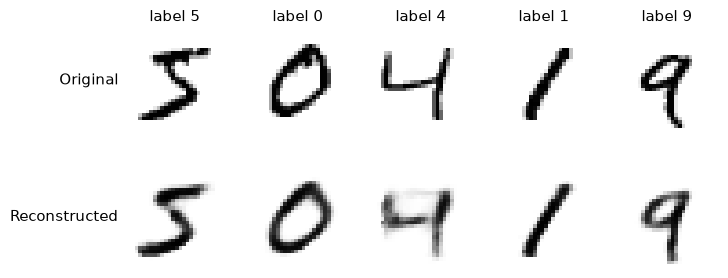

In [7]:
def plot_rows(rows, row_titles, col_titles=None):
    """Plots several rows of images; each row is a tensor of shape [n, 1, 28, 28]."""
    n_rows, n_cols = len(rows), len(rows[0])
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 1.5, n_rows * 1.6),
                             squeeze=False)
    for r, (images, title) in enumerate(zip(rows, row_titles)):
        for c in range(n_cols):
            ax = axes[r, c]
            ax.imshow(images[c].squeeze(0).detach().cpu().clamp(0, 1),
                      cmap="binary", vmin=0, vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
            if r == 0 and col_titles is not None:
                ax.set_title(col_titles[c], fontsize=11)
        axes[r, 0].set_ylabel(title, rotation=0, ha="right", va="center", fontsize=11)
    plt.tight_layout()
    plt.show()

def reconstruct(model, images):
    model.eval()  # important for the dropout models in Problem 5
    with torch.no_grad():
        y_pred = model(images.to(device))
    if isinstance(y_pred, tuple):
        y_pred = y_pred.output
    return y_pred.cpu()

# first 5 elements of the MNIST data set
first5 = torch.stack([mnist_train_and_valid[i][0] for i in range(5)])
first5_labels = [mnist_train_and_valid[i][1] for i in range(5)]

plot_rows([first5, reconstruct(stacked_ae, first5)],
          ["Original", "Reconstructed"],
          col_titles=[f"label {y}" for y in first5_labels])

The reconstructions are recognizable but somewhat blurry, which is expected: each 784-pixel image is squeezed through a 32-number coding layer.

## Problem 3. 
Pass 4 images from the Fashion MNIST data set to the autoencoder trained in Problem 2 and present their reconstructed images. This is a demonstration of the anomaly detection. Calculate the loss value that such autoencoder produces for MNIST images and the loss values for Fashion MNIST images. Compare

100%|██████████| 26.4M/26.4M [00:03<00:00, 8.35MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 278kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.91MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 1.04MB/s]


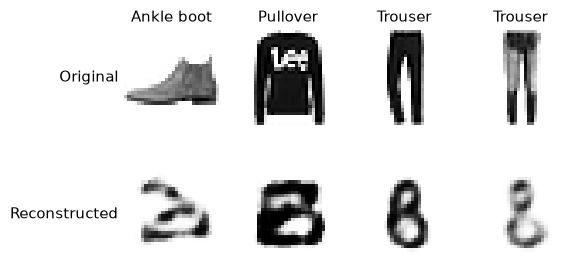

In [8]:
fashion_data = torchvision.datasets.FashionMNIST(
    root="datasets", train=False, download=True, transform=toTensor)
X_fashion = torch.stack([fashion_data[i][0] for i in range(len(X_mnist_valid))])

fashion_classes = fashion_data.classes
fashion4 = X_fashion[:4]
plot_rows([fashion4, reconstruct(stacked_ae, fashion4)],
          ["Original", "Reconstructed"],
          col_titles=[fashion_classes[fashion_data[i][1]] for i in range(4)])

The MNIST-trained autoencoder can only "speak digit": it tries to turn every input into something digit-like, so clothing items are reconstructed poorly. That is exactly what makes a high reconstruction loss a useful anomaly signal.

Now compare per-image reconstruction losses (MSE) for 5,000 unseen MNIST validation images vs. 5,000 Fashion MNIST images:

Loss on the 5 MNIST images (Problem 2): ['0.0223', '0.0111', '0.0183', '0.0021', '0.0184']
Loss on the 4 Fashion images above:     ['0.0744', '0.2040', '0.1137', '0.0790']

Mean loss, MNIST validation set   : 0.0145
Mean loss, Fashion MNIST images   : 0.1042
Ratio Fashion / MNIST             : 7.2x

Threshold (99th pct of MNIST losses): 0.0410
Fashion images flagged as anomalies : 87.2%
MNIST images flagged (false alarms) : 1.0%


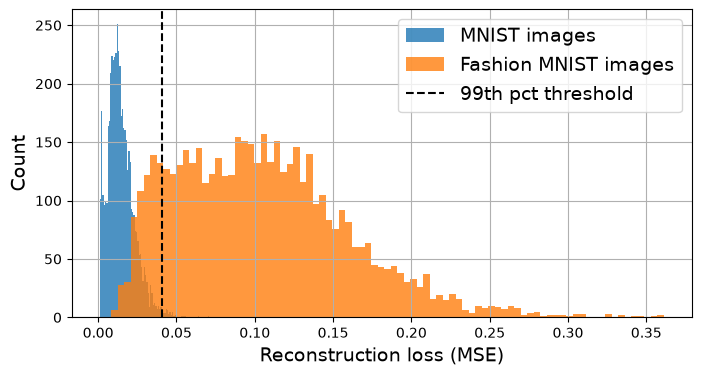

In [9]:
def compute_reconstruction_losses(model, X, batch_size=1000):
    """Per-image MSE between each image and its reconstruction."""
    model.eval()
    losses = []
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            X_batch = X[i:i + batch_size].to(device)
            y_pred = model(X_batch)
            losses.append(F.mse_loss(y_pred, X_batch, reduction="none")
                          .flatten(start_dim=1).mean(dim=1).cpu())
    return torch.cat(losses)

losses_first5_mnist = compute_reconstruction_losses(stacked_ae, first5)
losses_fashion4 = compute_reconstruction_losses(stacked_ae, fashion4)
losses_mnist = compute_reconstruction_losses(stacked_ae, X_mnist_valid)
losses_fashion = compute_reconstruction_losses(stacked_ae, X_fashion)

print("Loss on the 5 MNIST images (Problem 2):", [f"{l:.4f}" for l in losses_first5_mnist.tolist()])
print("Loss on the 4 Fashion images above:    ", [f"{l:.4f}" for l in losses_fashion4.tolist()])
print()
print(f"Mean loss, MNIST validation set   : {losses_mnist.mean().item():.4f}")
print(f"Mean loss, Fashion MNIST images   : {losses_fashion.mean().item():.4f}")
print(f"Ratio Fashion / MNIST             : {(losses_fashion.mean() / losses_mnist.mean()).item():.1f}x")

# simple anomaly detector: flag anything above the 99th percentile of MNIST losses
threshold = torch.quantile(losses_mnist, 0.99).item()
print(f"\nThreshold (99th pct of MNIST losses): {threshold:.4f}")
print(f"Fashion images flagged as anomalies : {(losses_fashion > threshold).float().mean().item():.1%}")
print(f"MNIST images flagged (false alarms) : {(losses_mnist > threshold).float().mean().item():.1%}")

plt.figure(figsize=(8, 4))
plt.hist(losses_mnist, bins=85, alpha=0.8, label="MNIST images")
plt.hist(losses_fashion, bins=85, alpha=0.8, label="Fashion MNIST images")
plt.axvline(threshold, color="k", linestyle="--", label="99th pct threshold")
plt.xlabel("Reconstruction loss (MSE)")
plt.ylabel("Count")
plt.legend()
plt.grid()
plt.show()

**Comparison.** The reconstruction loss on Fashion MNIST images is several times larger on average than on MNIST images the autoencoder has never seen (see the printed ratio), and the two histograms barely overlap. The autoencoder learned to reconstruct digits well, but Fashion MNIST images lie far from that data distribution, so they reconstruct badly. Thresholding the reconstruction loss therefore gives a simple anomaly detector: with the threshold set at the 99th percentile of MNIST losses, only about 1% of digits are falsely flagged while the large majority of fashion images are caught.

## Problem 4. 
Please generate a 2D t-SNE display for MNIST data set similar to the display on slide 49. 

As on slide 49: compress the 5,000 validation images to 32 numbers with the stacked encoder from Problem 2, then reduce those codings to 2D with t-SNE.

In [10]:
from sklearn.manifold import TSNE

stacked_encoder.eval()
with torch.no_grad():
    X_valid_compressed = stacked_encoder(X_mnist_valid.to(device)).cpu()

tsne = TSNE(init="pca", learning_rate="auto", random_state=42)
X_valid_2D = tsne.fit_transform(X_valid_compressed.numpy())

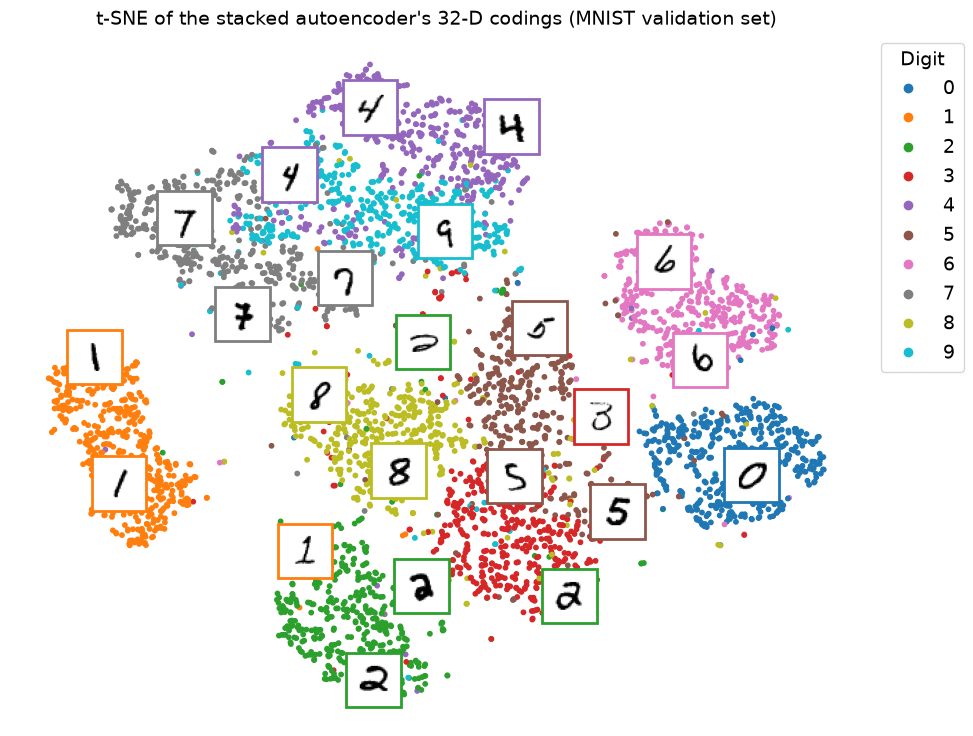

In [11]:
from matplotlib.offsetbox import AnnotationBbox, OffsetImage

plt.figure(figsize=(11, 9))
cmap = plt.cm.tab10
Z = (X_valid_2D - X_valid_2D.min()) / (X_valid_2D.max() - X_valid_2D.min())  # normalize to 0-1
scatter = plt.scatter(Z[:, 0], Z[:, 1], c=y_mnist_valid.numpy(), s=10, cmap=cmap)

image_positions = np.array([[1., 1.]])
for index, position in enumerate(Z):
    dist = ((position - image_positions) ** 2).sum(axis=1)
    if dist.min() > 0.02:  # only if far enough from images already drawn
        image_positions = np.r_[image_positions, [position]]
        imagebox = AnnotationBbox(
            OffsetImage(X_mnist_valid[index].squeeze(dim=0).numpy(), cmap="binary"),
            position, bboxprops={"edgecolor": cmap(int(y_mnist_valid[index])), "lw": 2})
        plt.gca().add_artist(imagebox)

plt.legend(*scatter.legend_elements(), title="Digit",
           loc="upper left", bbox_to_anchor=(1.01, 1))
plt.title("t-SNE of the stacked autoencoder's 32-D codings (MNIST validation set)")
plt.axis("off")
plt.show()

The digits form clearly separated clusters, even though the autoencoder never saw the labels. Visually similar digits (e.g. 4 / 9, 3 / 5 / 8) end up in neighboring or partially overlapping clusters.

## Problem 5. 
Implement a convolutional denoising autoencoder with dropout layer and 
train it with MNIST data set. As the dropout parameter use 0.20. Produce 5 original images of random digits and their reconstructed images. Change the dropout parameter to 0.10 and compare new reconstructed images with the previous one. Just produce a qualitative assessment of the change in quality of the reconstructed images if any.  (20%) 

The convolutional autoencoder is Géron's `conv_encoder` / `conv_decoder`, with an `nn.Dropout` layer added at the input. Dropout randomly zeroes input pixels during training only, so the network learns to reconstruct the clean image from a corrupted one (denoising). In eval mode the dropout layer does nothing.

In [12]:
def make_conv_denoising_ae(dropout_rate):
    torch.manual_seed(42)
    conv_encoder = nn.Sequential(
        nn.Dropout(dropout_rate),  # corrupts the input (training only)
        nn.Conv2d(1, 16, kernel_size=3, padding="same"), nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),  # output: 16 × 14 × 14
        nn.Conv2d(16, 32, kernel_size=3, padding="same"), nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),  # output: 32 × 7 × 7
        nn.Conv2d(32, 64, kernel_size=3, padding="same"), nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),  # output: 64 × 3 × 3
        nn.Conv2d(64, 32, kernel_size=3, padding="same"), nn.ReLU(),
        nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten())  # output: 32
    conv_decoder = nn.Sequential(
        nn.Linear(32, 16 * 3 * 3),
        nn.Unflatten(dim=1, unflattened_size=(16, 3, 3)),
        nn.ConvTranspose2d(16, 32, kernel_size=3, stride=2), nn.ReLU(),  # 32 × 7 × 7
        nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1,
                           output_padding=1), nn.ReLU(),  # 16 × 14 × 14
        nn.ConvTranspose2d(16, 1, kernel_size=3, stride=2, padding=1,
                           output_padding=1), nn.Sigmoid())  # 1 × 28 × 28
    return nn.Sequential(conv_encoder, conv_decoder).to(device)

### Dropout = 0.20

In [13]:
conv_dae_20 = make_conv_denoising_ae(0.20)
optimizer = torch.optim.NAdam(conv_dae_20.parameters(), lr=0.005)
history_20 = train(conv_dae_20, optimizer, mse, rmse, train_loader, valid_loader,
                   n_epochs=10)

MIOpen(HIP): Warning [OpenRuntimeLibraryForDevice] CK grouped conv library not found for device gfx1030: libMIOpenCKGroupedConv_gfx1030.so: cannot open shared object file: No such file or directory


Epoch 1/10,                      train loss: 0.0342, train metric: 0.185, valid metric: 0.142
Epoch 2/10,                      train loss: 0.0172, train metric: 0.131, valid metric: 0.128
Epoch 3/10,                      train loss: 0.0140, train metric: 0.118, valid metric: 0.121
Epoch 4/10,                      train loss: 0.0126, train metric: 0.112, valid metric: 0.138
Epoch 5/10,                      train loss: 0.0108, train metric: 0.104, valid metric: 0.124
Epoch 6/10,                      train loss: 0.0105, train metric: 0.102, valid metric: 0.128
Epoch 7/10,                      train loss: 0.0102, train metric: 0.101, valid metric: 0.135
Epoch 8/10,                      train loss: 0.0097, train metric: 0.0983, valid metric: 0.127
Epoch 9/10,                      train loss: 0.0096, train metric: 0.0977, valid metric: 0.131
Epoch 10/10,                      train loss: 0.0095, train metric: 0.0972, valid metric: 0.13


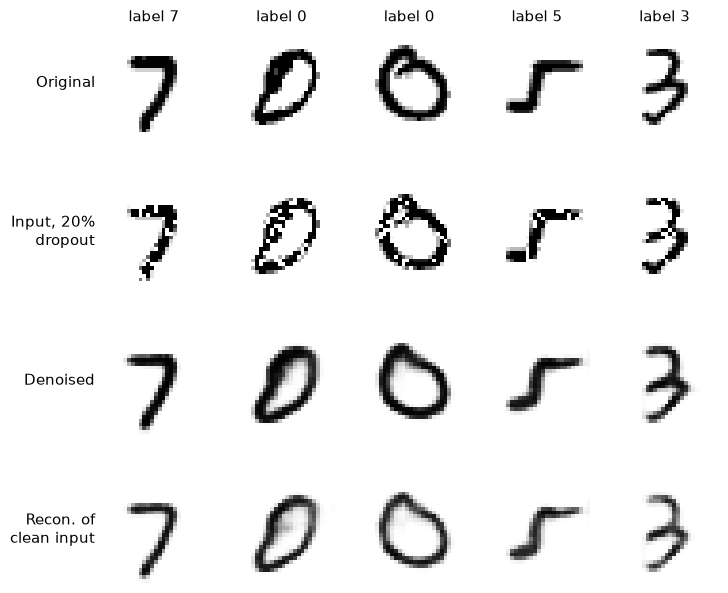

In [14]:
# 5 random digits from the validation set (same ones are reused for the 0.10 model)
gen = torch.Generator().manual_seed(7)
rand_idx = torch.randint(0, len(X_mnist_valid), (5,), generator=gen)
rand_digits = X_mnist_valid[rand_idx]
rand_labels = [f"label {y}" for y in y_mnist_valid[rand_idx].tolist()]

def corrupt(X, p, seed=42):
    """Apply the same kind of corruption the model saw in training (input dropout)."""
    torch.manual_seed(seed)
    return F.dropout(X, p=p, training=True)

noisy_20 = corrupt(rand_digits, 0.20)
plot_rows([rand_digits, noisy_20,
           reconstruct(conv_dae_20, noisy_20), reconstruct(conv_dae_20, rand_digits)],
          ["Original", "Input, 20%\ndropout", "Denoised", "Recon. of\nclean input"],
          col_titles=rand_labels)

### Dropout = 0.10

In [15]:
conv_dae_10 = make_conv_denoising_ae(0.10)
optimizer = torch.optim.NAdam(conv_dae_10.parameters(), lr=0.005)
history_10 = train(conv_dae_10, optimizer, mse, rmse, train_loader, valid_loader,
                   n_epochs=10)

Epoch 1/10,                      train loss: 0.0348, train metric: 0.186, valid metric: 0.138
Epoch 2/10,                      train loss: 0.0166, train metric: 0.129, valid metric: 0.118
Epoch 3/10,                      train loss: 0.0137, train metric: 0.117, valid metric: 0.112
Epoch 4/10,                      train loss: 0.0124, train metric: 0.111, valid metric: 0.114
Epoch 5/10,                      train loss: 0.0107, train metric: 0.104, valid metric: 0.106
Epoch 6/10,                      train loss: 0.0104, train metric: 0.102, valid metric: 0.107
Epoch 7/10,                      train loss: 0.0101, train metric: 0.101, valid metric: 0.106
Epoch 8/10,                      train loss: 0.0096, train metric: 0.0981, valid metric: 0.101
Epoch 9/10,                      train loss: 0.0095, train metric: 0.0975, valid metric: 0.103
Epoch 10/10,                      train loss: 0.0094, train metric: 0.0969, valid metric: 0.103


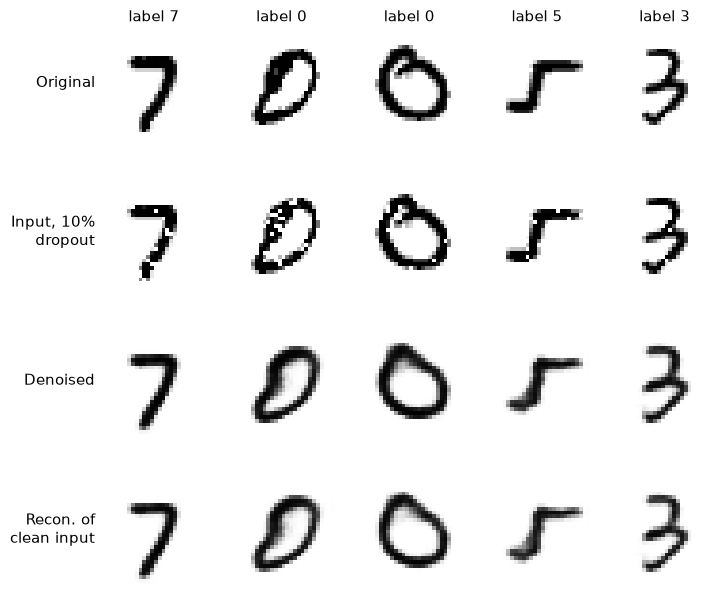

In [16]:
noisy_10 = corrupt(rand_digits, 0.10)
plot_rows([rand_digits, noisy_10,
           reconstruct(conv_dae_10, noisy_10), reconstruct(conv_dae_10, rand_digits)],
          ["Original", "Input, 10%\ndropout", "Denoised", "Recon. of\nclean input"],
          col_titles=rand_labels)

### Side-by-side comparison

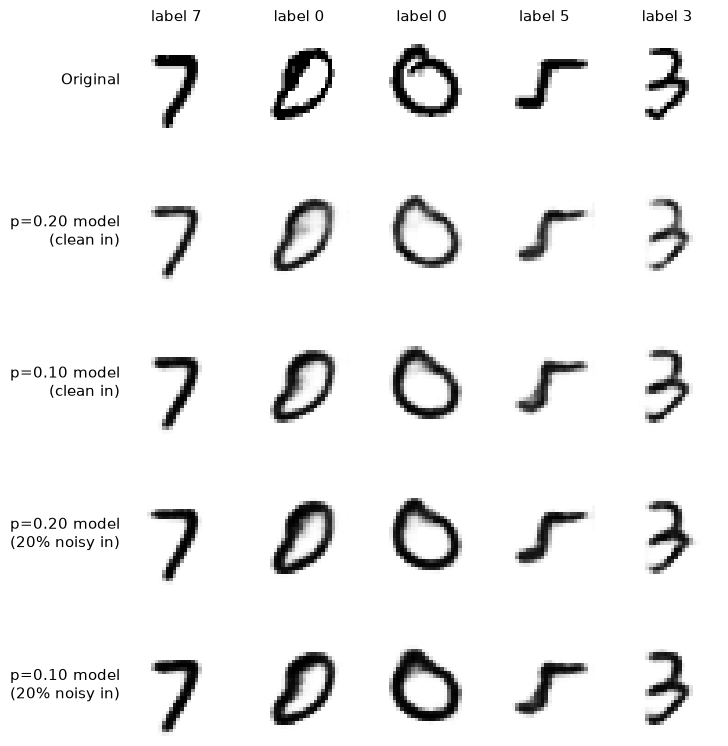

validation RMSE     clean input  10% dropped  20% dropped
p=0.20 model             0.1296       0.1076       0.0980
p=0.10 model             0.1025       0.0975       0.1036


In [17]:
plot_rows([rand_digits,
           reconstruct(conv_dae_20, rand_digits),
           reconstruct(conv_dae_10, rand_digits),
           reconstruct(conv_dae_20, noisy_20),
           reconstruct(conv_dae_10, noisy_20)],
          ["Original", "p=0.20 model\n(clean in)", "p=0.10 model\n(clean in)",
           "p=0.20 model\n(20% noisy in)", "p=0.10 model\n(20% noisy in)"],
          col_titles=rand_labels)

def rmse_with_corruption(model, X, p, batch_size=1000):
    """Validation RMSE when the input is corrupted with dropout rate p (target = clean)."""
    torch.manual_seed(0)
    model.eval()
    sq_err = 0.0
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            X_batch = X[i:i + batch_size].to(device)
            inputs = F.dropout(X_batch, p=p, training=True) if p > 0 else X_batch
            sq_err += F.mse_loss(model(inputs), X_batch, reduction="sum").item()
    return (sq_err / X.numel()) ** 0.5

print(f"{'validation RMSE':<18}{'clean input':>13}{'10% dropped':>13}{'20% dropped':>13}")
for name, model in [("p=0.20 model", conv_dae_20), ("p=0.10 model", conv_dae_10)]:
    scores = [rmse_with_corruption(model, X_mnist_valid, p) for p in (0.0, 0.10, 0.20)]
    print(f"{name:<18}" + "".join(f"{s:>13.4f}" for s in scores))

**Qualitative assessment.** Lowering the dropout rate from 0.20 to 0.10 changes the reconstructions only slightly. The digits are equally recognizable in both cases, and both sets stay somewhat blurry, because the dominant limitation is the 32-number bottleneck, not the dropout. With 0.10 dropout the training task is easier, so reconstructions of clean inputs tend to be marginally sharper and closer to the originals (thinner, better-defined strokes, a slightly lower clean-input RMSE). The 0.20 model, trained on harder corruption, is a bit smoother and copes better when the input is heavily corrupted (compare the last two rows and the 20% column of the table). In short, there is a small trade-off between reconstruction fidelity (lower dropout) and robustness to noise (higher dropout), but at these rates the visual difference is minor.

## Problem 6. 
Train a Variational Autoencoder on MNIST dataset with coding dimension 
of 2. Pick the mean coding values for two random images of two digits, for example 3 and 7. Create a set of 20 values uniformly distributed between those two coding values. Generate reconstruction images for every one of those coding values and present them as a 5x4 matrix

Géron's VAE from the chapter, with `codings_dim=2`. The encoder outputs a mean and log-variance for each coding dimension; the loss is reconstruction MSE plus the KL-divergence term.

In [18]:
from collections import namedtuple

VAEOutput = namedtuple("VAEOutput", ["output", "codings_mean", "codings_logvar"])

class VAE(nn.Module):
    def __init__(self, codings_dim=32):
        super().__init__()
        self.codings_dim = codings_dim
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(1 * 28 * 28, 128), nn.ReLU(),
            nn.Linear(128, 2 * codings_dim))  # outputs both the mean and logvar
        self.decoder = nn.Sequential(
            nn.Linear(codings_dim, 128), nn.ReLU(),
            nn.Linear(128, 1 * 28 * 28), nn.Sigmoid(),
            nn.Unflatten(dim=1, unflattened_size=(1, 28, 28)))

    def encode(self, X):
        return self.encoder(X).chunk(2, dim=-1)  # (mean, logvar)

    def sample_codings(self, codings_mean, codings_logvar):
        codings_std = torch.exp(0.5 * codings_logvar)
        noise = torch.randn_like(codings_std)
        return codings_mean + noise * codings_std

    def decode(self, Z):
        return self.decoder(Z)

    def forward(self, X):
        codings_mean, codings_logvar = self.encode(X)
        codings = self.sample_codings(codings_mean, codings_logvar)
        output = self.decode(codings)
        return VAEOutput(output, codings_mean, codings_logvar)

def vae_loss(y_pred, y_target, kl_weight=1.0):
    output, mean, logvar = y_pred
    kl_div = -0.5 * torch.sum(1 + logvar - logvar.exp() - mean.square(), dim=-1)
    return F.mse_loss(output, y_target) + kl_weight * kl_div.mean() / 784

In [19]:
torch.manual_seed(42)
vae = VAE(codings_dim=2).to(device)
optimizer = torch.optim.NAdam(vae.parameters(), lr=1e-3)
history_vae = train(vae, optimizer, vae_loss, rmse, train_loader, valid_loader,
                    n_epochs=20)

Epoch 1/20,                      train loss: 0.0609, train metric: 0.238, valid metric: 0.226
Epoch 2/20,                      train loss: 0.0542, train metric: 0.224, valid metric: 0.221
Epoch 3/20,                      train loss: 0.0528, train metric: 0.22, valid metric: 0.218
Epoch 4/20,                      train loss: 0.0519, train metric: 0.217, valid metric: 0.216
Epoch 5/20,                      train loss: 0.0511, train metric: 0.215, valid metric: 0.215
Epoch 6/20,                      train loss: 0.0509, train metric: 0.214, valid metric: 0.214
Epoch 7/20,                      train loss: 0.0506, train metric: 0.213, valid metric: 0.213
Epoch 8/20,                      train loss: 0.0503, train metric: 0.213, valid metric: 0.213
Epoch 9/20,                      train loss: 0.0502, train metric: 0.212, valid metric: 0.212
Epoch 10/20,                      train loss: 0.0501, train metric: 0.212, valid metric: 0.212
Epoch 11/20,                      train loss: 0.0499, train 

mean coding of the 3: [0.42297867 0.07827821]
mean coding of the 7: [-1.1147482  -0.02489854]


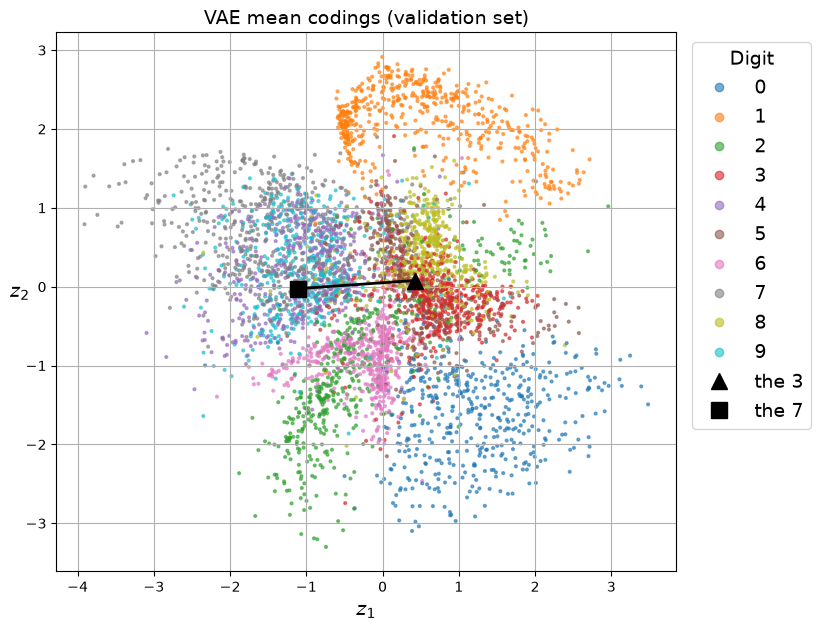

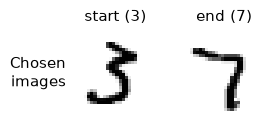

In [20]:
# mean codings of all validation images
vae.eval()
with torch.no_grad():
    codings_mean, _ = vae.encode(X_mnist_valid.to(device))
codings_mean = codings_mean.cpu()

# pick one random "3" and one random "7"
gen = torch.Generator().manual_seed(42)
def random_index_of(digit):
    candidates = (y_mnist_valid == digit).nonzero().flatten()
    return candidates[torch.randint(len(candidates), (1,), generator=gen)].item()

idx_start, idx_end = random_index_of(3), random_index_of(7)
z_start, z_end = codings_mean[idx_start], codings_mean[idx_end]
print(f"mean coding of the 3: {z_start.numpy()}")
print(f"mean coding of the 7: {z_end.numpy()}")

# 2D latent space, with the two chosen points and the interpolation path
plt.figure(figsize=(8, 7))
sc = plt.scatter(codings_mean[:, 0].numpy(), codings_mean[:, 1].numpy(), c=y_mnist_valid.numpy(),
                 s=4, cmap="tab10", alpha=0.6)
(x0, y0), (x1, y1) = z_start.tolist(), z_end.tolist()
plt.plot([x0, x1], [y0, y1], "k-", lw=2)
start_marker, = plt.plot(x0, y0, "k^", markersize=12)
end_marker, = plt.plot(x1, y1, "ks", markersize=12)
handles, labels = sc.legend_elements()
plt.legend(handles + [start_marker, end_marker], labels + ["the 3", "the 7"],
           title="Digit", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.xlabel("$z_1$")
plt.ylabel("$z_2$", rotation=0)
plt.title("VAE mean codings (validation set)")
plt.grid(True)
plt.show()

plot_rows([X_mnist_valid[[idx_start, idx_end]]], ["Chosen\nimages"],
          col_titles=["start (3)", "end (7)"])

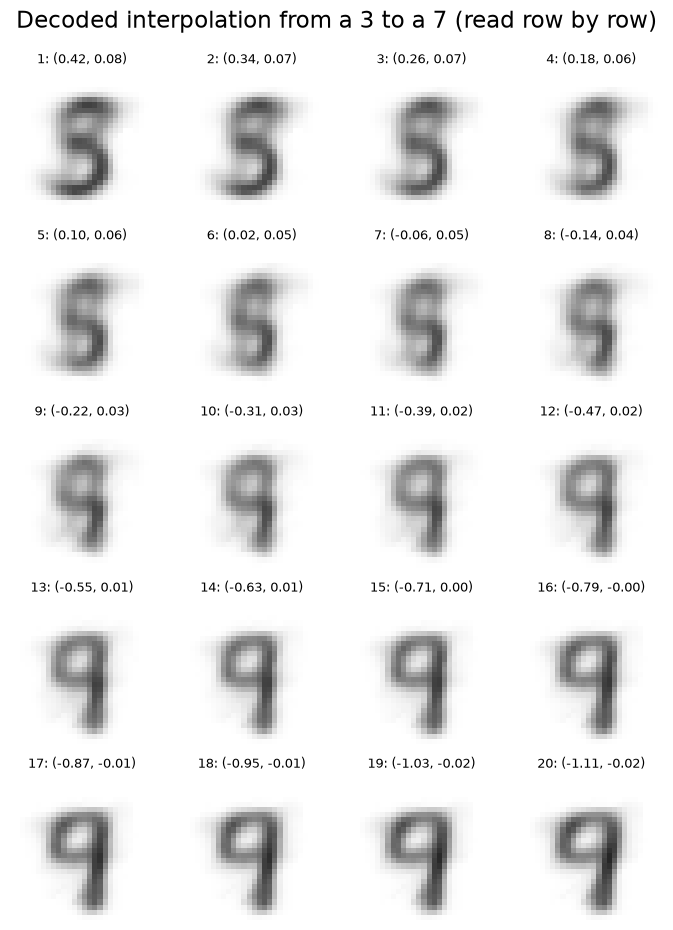

In [21]:
# 20 codings uniformly spaced on the segment between the two mean codings
n_steps = 20
weights = torch.linspace(0, 1, n_steps).view(n_steps, 1)
interp_codings = torch.lerp(z_start, z_end, weights)  # shape [20, 2]

with torch.no_grad():
    interp_images = vae.decode(interp_codings.to(device)).cpu()

fig, axes = plt.subplots(5, 4, figsize=(7, 9.5))
for k, ax in enumerate(axes.flat):
    ax.imshow(interp_images[k].squeeze(0), cmap="binary", vmin=0, vmax=1)
    z1, z2 = interp_codings[k].tolist()
    ax.set_title(f"{k + 1}: ({z1:.2f}, {z2:.2f})", fontsize=9)
    ax.axis("off")
plt.suptitle("Decoded interpolation from a 3 to a 7 (read row by row)")
plt.tight_layout()
plt.show()

Reading the 5×4 matrix row by row, the decoded images morph gradually from the 3 into the 7. Because the latent space is only 2D, the straight line between the two codings can pass through regions belonging to other digits (see the latent-space plot above), so some intermediate images may look like a different digit before the 7 emerges. The smoothness of the transition shows that the VAE's latent space is continuous: nearby codings decode to similar images.